# Web APIs

Cells have the web platform's `fetch`, so any API that allows requests
from a web page (CORS) is a few lines away. These use public APIs that need
no key.

## A JSON API: Wikipedia

In [1]:
async function getJson<T = any>(url: string): Promise<T> {
  // jupyter.signal aborts when you interrupt the kernel, so a slow request stops too.
  const response = await fetch(url, { signal: jupyter.signal });
  if (!response.ok) throw new Error(`${response.status} ${response.statusText}: ${url}`);
  return response.json();
}

const page = await getJson("https://en.wikipedia.org/api/rest_v1/page/summary/Ganymede_(moon)");
jupyter.md`### ${page.title}

${page.extract}

[Read more on Wikipedia](${page.content_urls.desktop.page})`;

### Ganymede (moon)

Ganymede is a natural satellite of Jupiter and is the largest and most massive moon in the Solar System. Like Saturn's largest moon, Titan, it is larger than the planet Mercury, but has somewhat less surface gravity than Mercury, Io, or Earth's Moon due to its lower density compared to the three. Ganymede orbits Jupiter in roughly seven days and is in a 1:2:4 orbital resonance with the moons Europa and Io, respectively.

[Read more on Wikipedia](https://en.wikipedia.org/wiki/Ganymede_(moon))

## Live data: this week's earthquakes

The US Geological Survey publishes earthquakes as GeoJSON, updated every
few minutes. Reshape the features into rows, then show the strongest.

In [2]:
const quakes = await getJson("https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_week.geojson");
type Quake = { place: string; magnitude: number; time: Date; depthKm: number; lon: number; lat: number };
const rows: Quake[] = quakes.features.map((f: any) => ({
  place: f.properties.place ?? "unknown",
  magnitude: f.properties.mag,
  time: new Date(f.properties.time),
  lon: f.geometry.coordinates[0],
  lat: f.geometry.coordinates[1],
  depthKm: f.geometry.coordinates[2],
}));
const strongest = [...rows].sort((a, b) => b.magnitude - a.magnitude).slice(0, 8);
jupyter.md`**${rows.length}** earthquakes of magnitude 4.5 or more in the past week.

| Magnitude | Where | When (UTC) | Depth (km) |
| ---: | :--- | :--- | ---: |
${strongest.map(q => `| ${q.magnitude.toFixed(1)} | ${q.place} | ${q.time.toISOString().slice(0, 16).replace("T", " ")} | ${q.depthKm.toFixed(0)} |`).join("\n")}`;

**79** earthquakes of magnitude 4.5 or more in the past week.

| Magnitude | Where | When (UTC) | Depth (km) |
| ---: | :--- | :--- | ---: |
| 6.4 | 30 km WSW of Lata, Solomon Islands | 2026-11-09 03:34 | 17 |
| 6.1 | 144 km SE of Hasaki, Japan | 2026-11-06 10:39 | 29 |
| 6.1 | Fiji region | 2026-11-05 17:21 | 535 |
| 5.8 | central Mid-Atlantic Ridge | 2026-11-07 23:17 | 10 |
| 5.7 | 106 km ENE of Hasaki, Japan | 2026-11-09 04:52 | 24 |
| 5.5 | 10 km NW of Hamakita, Japan | 2026-11-07 16:04 | 38 |
| 5.5 | 74 km NE of Hasaki, Japan | 2026-11-07 11:07 | 32 |
| 5.4 | 24 km NNW of Rioblanco, Colombia | 2026-11-03 09:13 | 10 |

And on a map, drawn as SVG: longitude and latitude straight to x and y, the
circle's size from the magnitude.

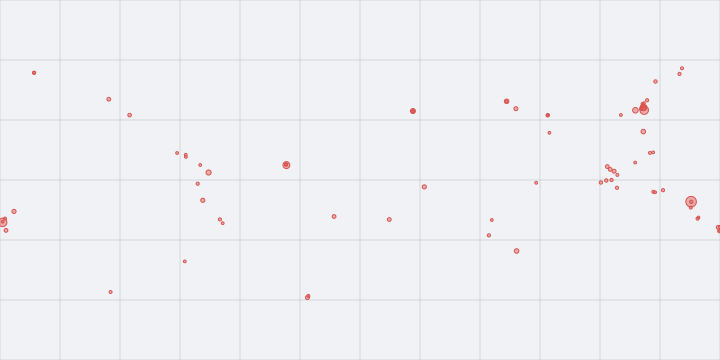

In [3]:
const W = 720, H = 360;
const x = (lon: number) => ((lon + 180) / 360) * W;
const y = (lat: number) => ((90 - lat) / 180) * H;
const grid = [];
for (let lon = -180; lon <= 180; lon += 30) grid.push(`<line x1="${x(lon)}" y1="0" x2="${x(lon)}" y2="${H}"/>`);
for (let lat = -90; lat <= 90; lat += 30) grid.push(`<line x1="0" y1="${y(lat)}" x2="${W}" y2="${y(lat)}"/>`);
const dots = rows.map(q =>
  `<circle cx="${x(q.lon).toFixed(1)}" cy="${y(q.lat).toFixed(1)}" r="${(2 ** (q.magnitude - 4)).toFixed(1)}"><title>${q.magnitude} ${q.place}</title></circle>`);
jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="${W}" height="${H}" viewBox="0 0 ${W} ${H}">
  <rect width="${W}" height="${H}" fill="#7a8ca61a"/>
  <g stroke="#88888840">${grid.join("")}</g>
  <g fill="#d9534f" fill-opacity="0.45" stroke="#d9534f">${dots.join("")}</g>
</svg>`;

## Several requests at once: npm downloads

`Promise.all` runs requests side by side. The progress line updates in
place as each one finishes.

In [4]:
const packages = ["react", "vue", "svelte", "preact", "solid-js", "lit"];
let done = 0;
await jupyter.display(jupyter.md`Fetching 0 of ${packages.length}…`, { display_id: "npm" });
const downloads = await Promise.all(
  packages.map(async name => {
    const d = await getJson(`https://api.npmjs.org/downloads/point/last-week/${name}`);
    done++;
    await jupyter.display(jupyter.md`Fetching ${done} of ${packages.length}…`, { display_id: "npm", update: true });
    return { name, downloads: d.downloads as number };
  }),
);
await jupyter.display(jupyter.md`Fetched ${packages.length} packages.`, { display_id: "npm", update: true });
downloads.sort((a, b) => b.downloads - a.downloads);
const most = downloads[0].downloads;
jupyter.html`<table>${downloads
  .map(d => `<tr><td>${d.name}</td><td style="text-align:right">${d.downloads.toLocaleString("en-US")}</td>
    <td><div style="background:#4f7cac;height:12px;width:${((d.downloads / most) * 260).toFixed(0)}px"></div></td></tr>`)
  .join("")}</table>`;

Fetched 6 packages.

react,"252,579,442",
preact,"57,099,391",
vue,"24,843,784",
solid-js,"11,164,298",
lit,"9,880,337",
svelte,"9,457,570",


## Errors from the network

A request the server refuses still resolves; check `response.ok`. A
request the network or CORS blocks rejects with a `TypeError`.

In [5]:
try {
  await getJson("https://api.github.com/repos/tlockney/no-such-repository");
} catch (e) {
  console.log((e as Error).message);
}

404 Not Found: https://api.github.com/repos/tlockney/no-such-repository


## Your own API

To try another API, change the URL. If it needs a key, keep the key out of
the notebook: on iPhone and iPad, `device.ui.prompt` can ask for it (see
**08 Device**).